In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

# 1. Load Data
df = pd.read_csv('ai4i2020.csv')

# 2. Feature Engineering & Selection
# Drop identifiers and the generic 'Machine failure' to focus on specific modes
X = df.drop(columns=['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'])

# Encode the 'Type' categorical column (L, M, H)
le = LabelEncoder()
X['Type'] = le.fit_transform(X['Type'])

# 3. Create Multi-class Target Variable
# 0: Healthy, 1: TWF, 2: HDF, 3: PWF, 4: OSF, 5: RNF
def determine_failure_mode(row):
    if row['TWF'] == 1: return 1
    elif row['HDF'] == 1: return 2
    elif row['PWF'] == 1: return 3
    elif row['OSF'] == 1: return 4
    elif row['RNF'] == 1: return 5
    else: return 0

y = df.apply(determine_failure_mode, axis=1)

# 4. Train-Test Split (Stratified to maintain class ratios before SMOTE)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Original training shape: {X_train_scaled.shape}")
print(f"Original class distribution:\n{y_train.value_counts()}")

Original training shape: (8000, 6)
Original class distribution:
0    7722
2      92
3      73
4      62
1      37
5      14
Name: count, dtype: int64


In [2]:
# Apply SMOTE to balance the training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print(f"Resampled training shape: {X_train_resampled.shape}")
print(f"Resampled class distribution:\n{y_train_resampled.value_counts()}")

Resampled training shape: (46332, 6)
Resampled class distribution:
0    7722
3    7722
1    7722
2    7722
4    7722
5    7722
Name: count, dtype: int64


In [3]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, recall_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize Models
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    random_state=42,
    # XGBoost can utilize GPU acceleration if CUDA is configured
    # tree_method='hist', device='cuda' 
)

rf_model = RandomForestClassifier(
    n_estimators=100, 
    random_state=42,
    class_weight='balanced'
)

# Train XGBoost
print("Training XGBoost...")
xgb_model.fit(X_train_resampled, y_train_resampled)

# Train Random Forest
print("Training Random Forest...")
rf_model.fit(X_train_resampled, y_train_resampled)

Training XGBoost...
Training Random Forest...


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False



--- XGBoost Performance ---
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      1930
           1       0.10      0.22      0.14         9
           2       0.96      0.96      0.96        23
           3       0.84      0.89      0.86        18
           4       0.84      1.00      0.91        16
           5       0.00      0.00      0.00         4

    accuracy                           0.97      2000
   macro avg       0.62      0.67      0.64      2000
weighted avg       0.98      0.97      0.98      2000



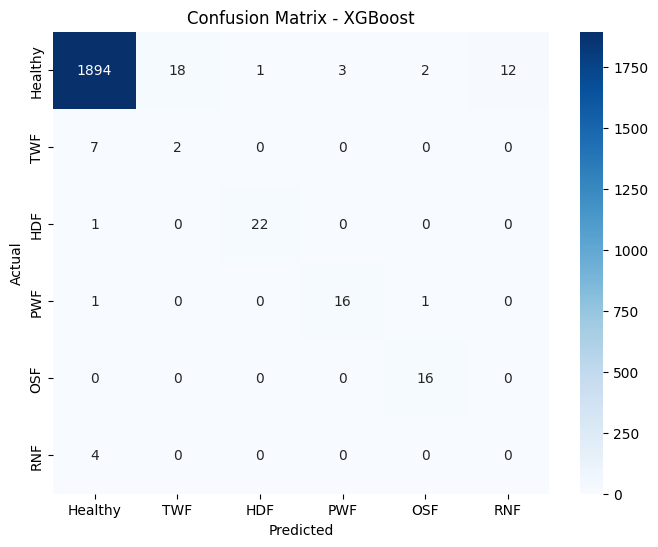


--- Random Forest Performance ---
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1930
           1       0.05      0.11      0.07         9
           2       0.79      0.83      0.81        23
           3       0.82      0.78      0.80        18
           4       0.76      1.00      0.86        16
           5       0.00      0.00      0.00         4

    accuracy                           0.97      2000
   macro avg       0.57      0.62      0.59      2000
weighted avg       0.98      0.97      0.97      2000



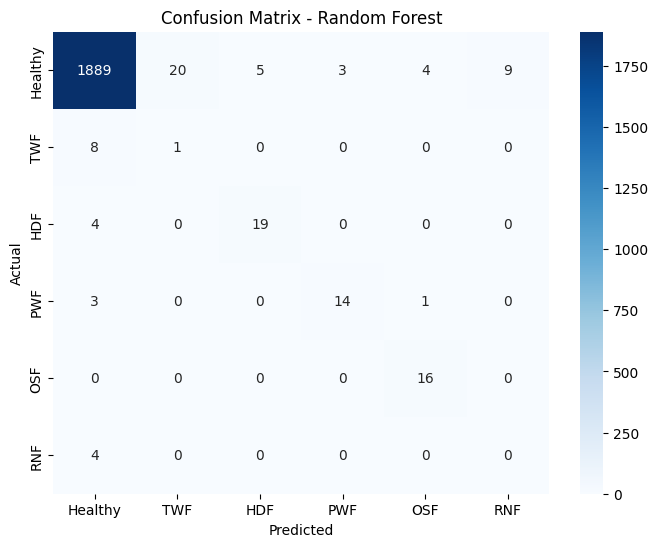

In [4]:
def evaluate_model(model, name):
    y_pred = model.predict(X_test_scaled)
    
    print(f"\n--- {name} Performance ---")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    # Plot Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Healthy', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
                yticklabels=['Healthy', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'])
    plt.title(f'Confusion Matrix - {name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

evaluate_model(xgb_model, "XGBoost")
evaluate_model(rf_model, "Random Forest")